In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
df = pd.read_csv(r"C:\Users\Krutika Shivanand\Downloads\Titanic-Dataset.csv")

print("First five rows:")
print(df.head())

print("\nDataset Information:")
print(df.info())

First five rows:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   

In [3]:
df = df.dropna(subset=['Fare'])

print("Number of records:", len(df))
print(df['Fare'].describe())

Number of records: 891
count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64


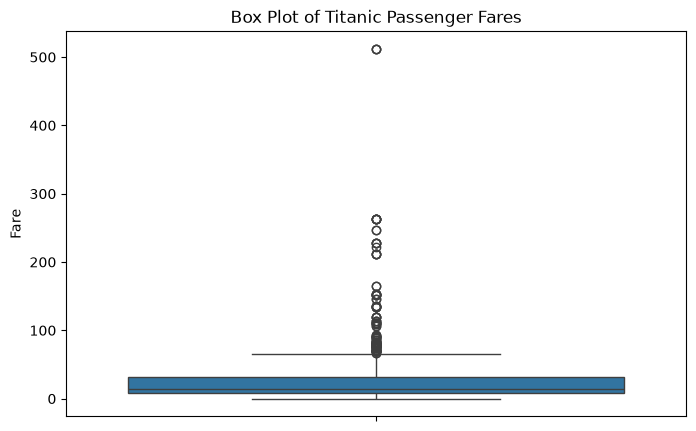

In [4]:
plt.figure(figsize=(8, 5))

sns.boxplot(y=df['Fare'])

plt.title("Box Plot of Titanic Passenger Fares")
plt.ylabel("Fare")

plt.show()

In [5]:
Q1 = df['Fare'].quantile(0.25)
Q3 = df['Fare'].quantile(0.75)

print("Q1 =", Q1)
print("Q3 =", Q3)

IQR = Q3 - Q1

print("IQR =", IQR)

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower Limit =", lower_limit)
print("Upper Limit =", upper_limit)

outliers_iqr = df[
    (df['Fare'] < lower_limit) |
    (df['Fare'] > upper_limit)
]

print("\nOutliers detected using IQR:")
print(outliers_iqr[['PassengerId', 'Fare']])

print("\nTotal IQR outliers:", len(outliers_iqr))

Q1 = 7.9104
Q3 = 31.0
IQR = 23.0896
Lower Limit = -26.724
Upper Limit = 65.6344

Outliers detected using IQR:
     PassengerId      Fare
1              2   71.2833
27            28  263.0000
31            32  146.5208
34            35   82.1708
52            53   76.7292
..           ...       ...
846          847   69.5500
849          850   89.1042
856          857  164.8667
863          864   69.5500
879          880   83.1583

[116 rows x 2 columns]

Total IQR outliers: 116


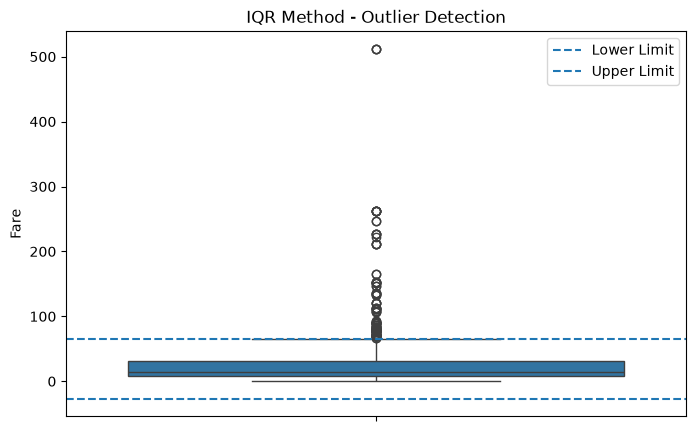

In [6]:
plt.figure(figsize=(8, 5))

sns.boxplot(y=df['Fare'])

plt.axhline(lower_limit, linestyle='--', label='Lower Limit')
plt.axhline(upper_limit, linestyle='--', label='Upper Limit')

plt.title("IQR Method - Outlier Detection")
plt.ylabel("Fare")
plt.legend()

plt.show()

In [7]:
df['Fare_IQR_Capped'] = df['Fare'].clip(
    lower=lower_limit,
    upper=upper_limit
)

print(df[['Fare', 'Fare_IQR_Capped']].head(20))

       Fare  Fare_IQR_Capped
0    7.2500           7.2500
1   71.2833          65.6344
2    7.9250           7.9250
3   53.1000          53.1000
4    8.0500           8.0500
5    8.4583           8.4583
6   51.8625          51.8625
7   21.0750          21.0750
8   11.1333          11.1333
9   30.0708          30.0708
10  16.7000          16.7000
11  26.5500          26.5500
12   8.0500           8.0500
13  31.2750          31.2750
14   7.8542           7.8542
15  16.0000          16.0000
16  29.1250          29.1250
17  13.0000          13.0000
18  18.0000          18.0000
19   7.2250           7.2250


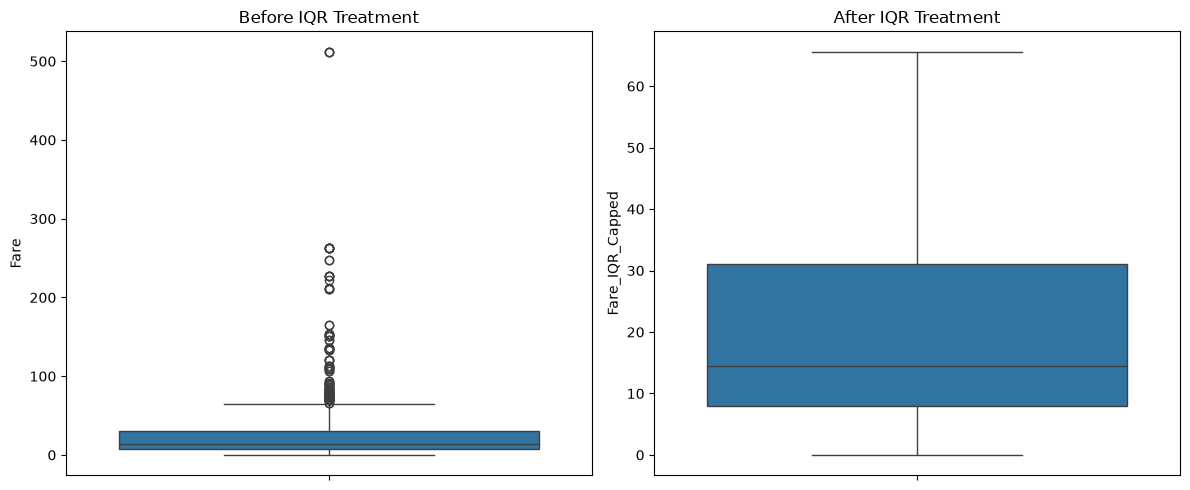

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df['Fare'], ax=axes[0])
axes[0].set_title("Before IQR Treatment")

sns.boxplot(y=df['Fare_IQR_Capped'], ax=axes[1])
axes[1].set_title("After IQR Treatment")

plt.tight_layout()
plt.show()

In [9]:
df['Z_score'] = stats.zscore(df['Fare'])

print(df[['Fare', 'Z_score']].head(20))

z_outliers = df[abs(df['Z_score']) > 3]

print("\nOutliers detected using Z-score:")
print(z_outliers[['PassengerId', 'Fare', 'Z_score']])

print("\nTotal Z-score outliers:", len(z_outliers))

       Fare   Z_score
0    7.2500 -0.502445
1   71.2833  0.786845
2    7.9250 -0.488854
3   53.1000  0.420730
4    8.0500 -0.486337
5    8.4583 -0.478116
6   51.8625  0.395814
7   21.0750 -0.224083
8   11.1333 -0.424256
9   30.0708 -0.042956
10  16.7000 -0.312172
11  26.5500 -0.113846
12   8.0500 -0.486337
13  31.2750 -0.018709
14   7.8542 -0.490280
15  16.0000 -0.326267
16  29.1250 -0.061999
17  13.0000 -0.386671
18  18.0000 -0.285997
19   7.2250 -0.502949

Outliers detected using Z-score:
     PassengerId      Fare   Z_score
27            28  263.0000  4.647001
88            89  263.0000  4.647001
118          119  247.5208  4.335332
258          259  512.3292  9.667167
299          300  247.5208  4.335332
311          312  262.3750  4.634417
341          342  263.0000  4.647001
377          378  211.5000  3.610065
380          381  227.5250  3.932723
438          439  263.0000  4.647001
527          528  221.7792  3.817033
557          558  227.5250  3.932723
679          680  512.3